# 24 - Correção de viés da humidade do solo (quantile mapping)

| | |
|---|---|
| **Tarefa do plano** | S2-07 - ajustar o ERA5-Land à escala do SMAP (calibração 2015–2021) |
| **O que faz** | Cria uma série de humidade do solo de 20 anos na escala do melhor sensor disponível |
| **Usa** | `hydromet_daily.csv` (notebook 23) |
| **Produz** | `data/processed/series/soil_moisture_calibrated_daily.csv` e `_monthly.csv` |

**O problema.** O ERA5-Land cobre os 20 anos, mas é um modelo. O SMAP é um
satélite feito para medir humidade do solo, mas só existe desde 2015. Os dois
sobem e descem juntos, só que em escalas diferentes.

**A solução (quantile mapping).** No período em que os dois existem, aprende-se
a correspondência entre eles: "quando o ERA5-Land está no seu valor dos 10 % mais
secos, o SMAP está em tal valor", e assim para todos os níveis. Depois aplica-se
essa tabela de conversão ao ERA5-Land dos 20 anos.

**Como se prova que funciona.** A conversão é aprendida só com 2015–2021 e
testada em 2022 em diante, anos que ela nunca viu.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, drivers, features, rasters, series, training
from ete import grid as G

cfg = config.load_config()
P = cfg["processing"]
REPORTS = config.path(cfg, "reports", "semana_2")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)

In [2]:
daily = drivers.read_table(cfg, "hydromet_daily")
cal = slice(P["calibration"]["start"], P["calibration"]["end"])
test = slice(str(int(P["calibration"]["end"][:4]) + 1), None)

# pares: série longa (ERA5-Land) -> série de referência (SMAP)
PAIRS = {"sm_cal": ("sm_era5_l1", "smap_surface"), "sm_root_cal": ("sm_era5_l2", "smap_rootzone")}

calibrated, rows = pd.DataFrame(index=daily.index), []
for out_name, (source, target) in PAIRS.items():
    for area in drivers.AREAS:
        s, t = daily[f"{source}_{area}"], daily[f"{target}_{area}"]
        qm = features.QuantileMapping().fit(s[cal], t[cal])
        calibrated[f"{out_name}_{area}"] = qm.transform(s.dropna()).reindex(daily.index)
        for period, label in [(cal, "calibração 2015-2021"), (test, "teste 2022+")]:
            for series_name, values in [("ERA5-Land original", s), ("ERA5-Land calibrado", calibrated[f"{out_name}_{area}"])]:
                rows.append({"variável": target, "área": area, "período": label, "série": series_name,
                             **features.agreement(t[period], values[period])})
resultado = pd.DataFrame(rows).set_index(["variável", "área", "período", "série"])
resultado.to_csv(REPORTS / "24_quantile_mapping_validacao.csv")
resultado

n    r2  \
variável      área     período              série                             
smap_surface  basin    calibração 2015-2021 ERA5-Land original   2467 0.793   
                                            ERA5-Land calibrado  2467 0.798   
                       teste 2022+          ERA5-Land original   1734 0.776   
                                            ERA5-Land calibrado  1734 0.784   
              district calibração 2015-2021 ERA5-Land original   2467 0.615   
                                            ERA5-Land calibrado  2467 0.644   
                       teste 2022+          ERA5-Land original   1734 0.530   
                                            ERA5-Land calibrado  1734 0.556   
smap_rootzone basin    calibração 2015-2021 ERA5-Land original   2467 0.795   
                                            ERA5-Land calibrado  2467 0.817   
                       teste 2022+          ERA5-Land original   1734 0.725   
                                            ERA5-Land calibrado  1734 0.740   
              district calibração 2015-2021 ERA5-Land original   2467 0.671   
                                            ERA5-Land calibrado  2467 0.684   
                       teste 2022+          ERA5-Land original   1734 0.592   
                                            ERA5-Land calibrado  1734 0.593   

                                                                  bias  rmse  \
variável      área     período              série                              
smap_surface  basin    calibração 2015-2021 ERA5-Land original   0.110 0.115   
                                            ERA5-Land calibrado  0.000 0.019   
                       teste 2022+          ERA5-Land original   0.108 0.115   
                                            ERA5-Land calibrado -0.009 0.024   
              district calibração 2015-2021 ERA5-Land original   0.109 0.118   
                                            ERA5-Land calibrado  0.000 0.024   
                       teste 2022+          ERA5-Land original   0.102 0.115   
                                            ERA5-Land calibrado -0.013 0.035   
smap_rootzone basin    calibração 2015-2021 ERA5-Land original   0.087 0.093   
                                            ERA5-Land calibrado  0.000 0.009   
                       teste 2022+          ERA5-Land original   0.096 0.103   
                                            ERA5-Land calibrado -0.004 0.014   
              district calibração 2015-2021 ERA5-Land original   0.123 0.129   
                                            ERA5-Land calibrado  0.000 0.012   
                       teste 2022+          ERA5-Land original   0.129 0.136   
                                            ERA5-Land calibrado -0.005 0.018   

                                                                 slope  
variável      área     período              série                       
smap_surface  basin    calibração 2015-2021 ERA5-Land original   1.408  
                                            ERA5-Land calibrado  0.895  
                       teste 2022+          ERA5-Land original   1.418  
                                            ERA5-Land calibrado  0.931  
              district calibração 2015-2021 ERA5-Land original   1.409  
                                            ERA5-Land calibrado  0.805  
                       teste 2022+          ERA5-Land original   1.207  
                                            ERA5-Land calibrado  0.730  
smap_rootzone basin    calibração 2015-2021 ERA5-Land original   2.079  
                                            ERA5-Land calibrado  0.907  
                       teste 2022+          ERA5-Land original   1.939  
                                            ERA5-Land calibrado  0.834  
              district calibração 2015-2021 ERA5-Land original   2.103  
                                            ERA5-Land calibrado  0.835  
                       teste 2022+  

**Como ler a tabela.** `bias` é a diferença média em relação ao SMAP (ideal: 0),
`rmse` o erro típico e `r2` o quanto as duas séries se acompanham (ideal: 1). O
que conta são as linhas de **teste**: se o viés e o erro baixam nos anos que não
entraram na calibração, a correção é fiável. O `r2` quase não muda, e é esperado:
a correção ajusta a escala, não a ordem dos valores.

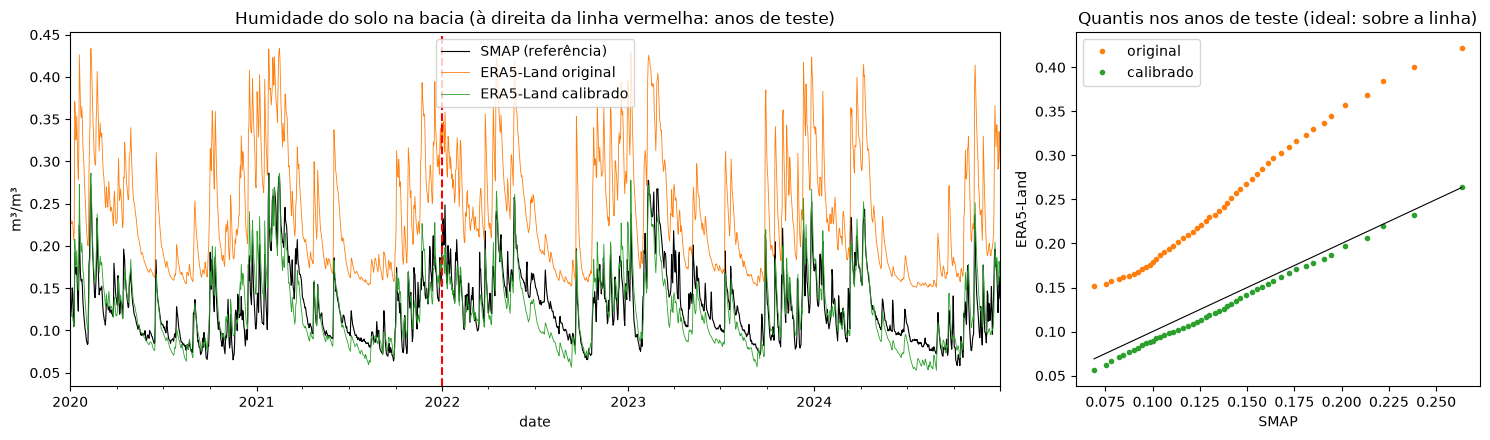

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), width_ratios=[2.3, 1])
window = slice("2020", "2024")
daily.loc[window, "smap_surface_basin"].plot(ax=axes[0], color="black", linewidth=0.8, label="SMAP (referência)")
daily.loc[window, "sm_era5_l1_basin"].plot(ax=axes[0], color="tab:orange", linewidth=0.6, label="ERA5-Land original")
calibrated.loc[window, "sm_cal_basin"].plot(ax=axes[0], color="tab:green", linewidth=0.6, label="ERA5-Land calibrado")
axes[0].axvline(pd.Timestamp(P["calibration"]["end"]), color="red", linestyle="--"); axes[0].legend(); axes[0].set_ylabel("m³/m³")
axes[0].set_title("Humidade do solo na bacia (à direita da linha vermelha: anos de teste)")
q = np.linspace(0.01, 0.99, 50)
ref_q = daily.loc[test, "smap_surface_basin"].quantile(q)
axes[1].plot(ref_q, daily.loc[test, "sm_era5_l1_basin"].quantile(q), "o", color="tab:orange", markersize=3, label="original")
axes[1].plot(ref_q, calibrated.loc[test, "sm_cal_basin"].quantile(q), "o", color="tab:green", markersize=3, label="calibrado")
axes[1].plot(ref_q, ref_q, color="black", linewidth=0.8); axes[1].legend()
axes[1].set_xlabel("SMAP"); axes[1].set_ylabel("ERA5-Land"); axes[1].set_title("Quantis nos anos de teste (ideal: sobre a linha)")
plt.tight_layout(); plt.savefig(REPORTS / "24_quantile_mapping.png", dpi=110)

In [4]:
calibrated.round(5).to_csv(drivers.table(cfg, "soil_moisture_calibrated_daily"))
monthly = features.month_index(calibrated.resample("MS").mean().where(calibrated.resample("MS").count() >= 25))
monthly.round(5).to_csv(drivers.table(cfg, "soil_moisture_calibrated_monthly"))
print("série calibrada:", calibrated["sm_cal_basin"].first_valid_index().date(), "a", calibrated["sm_cal_basin"].last_valid_index().date())
monthly.tail(3)

série calibrada: 2006-01-01 a 2026-09-30


,sm_cal_basin,sm_cal_district,sm_root_cal_basin,sm_root_cal_district
month,,,,
2026-08,0.113,0.134,0.153,0.135
2026-09,0.117,0.127,0.147,0.126
2026-10,NaN,NaN,NaN,NaN


**Limites a ter em conta**

- A correção é feita sobre a **média da área** (bacia e distrito), não célula a
  célula: as duas grelhas não coincidem e o distrito cabe em poucas células.
- `sm_root_cal` liga a camada 7–28 cm do ERA5-Land à zona radicular do SMAP
  (0–100 cm). As profundidades não são as mesmas, por isso é uma aproximação;
  a coluna principal a usar nos modelos é `sm_cal` (superfície).
- A correção assume que a relação entre os dois produtos em 2015–2021 também
  valia em 2006–2014. Não há forma de o verificar com estes dados.